# Flight disruption prediction (CDS 4003)
Salem Marwan Alebri (H00472169) and Ebrahim Abdulaziz Mohamed Ibrahim Almarzouqi (H00442189)

## 1. Business problem
Delays and cancellations create extra work for airline support staff. We want to predict from the planned schedule if a flight will be **disrupted** (cancelled, diverted, or arriving 15+ minutes late), so staff know which flights may need attention.
Goal: compare two models and pick the one with the better F1 score.

## 2. Dataset
- Source: [US DOT 2015 Flight Delays and Cancellations (Kaggle)](https://www.kaggle.com/datasets/usdot/flight-delays), licence CC0 Public Domain.
- The full file has 5,819,079 rows. We use a random sample of **250,000 rows and all 31 columns** (`data/flights.csv.gz`).
- The full file is too big for GitHub (590 MB), so we saved a sample. The commented code below shows how we made it.
- Other datasets we looked at are listed in the README.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

data = pd.read_csv('data/flights.csv.gz', dtype={'ORIGIN_AIRPORT': str, 'DESTINATION_AIRPORT': str})
print('Rows and columns:', data.shape)
display(data.head())

Rows and columns: (250000, 31)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,4,7,2,EV,4900,N759EV,FWA,DTW,1340,...,1423.0,-13.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,24,6,AS,611,N413AS,LAS,SEA,1910,...,2133.0,-12.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,7,8,3,WN,1483,N463WN,OAK,SEA,630,...,812.0,-8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,5,26,2,WN,193,N7745A,STL,DAL,810,...,1222.0,152.0,0,0,NaN,0.0,0.0,0.0,152.0,0.0
4,2015,7,6,1,UA,253,N213UA,IAH,HNL,1000,...,1316.0,-2.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# How the sample was made (only run this if you downloaded flights.csv from Kaggle):
# full = pd.read_csv('flights.csv', dtype={'ORIGIN_AIRPORT': str, 'DESTINATION_AIRPORT': str})
# full.sample(n=250000, random_state=42).to_csv('data/flights.csv.gz', index=False)

## 3. Data cleaning
First we check missing values, duplicates and basic statistics.

Cleaning decisions:
- Remove exact duplicates.
- Remove rows where the outcome is unknown (no arrival delay and not cancelled/diverted).
- Impossible values (distance or duration 0 or below, wrong clock times) become missing, then get filled with the median.
- Negative arrival delays are early arrivals, so we keep them. Long flights are real, so we keep them too.
- In October airport codes are numbers, not letters (inconsistent format). We do not use airports as inputs, so we leave them as they are.
- Columns recorded after the flight (actual times, delay causes) are **not** used as inputs.

In [3]:
print('Exact duplicates:', data.duplicated().sum())
display(data.isna().sum().sort_values(ascending=False).head(10).rename('Missing rows'))
display(data[['DISTANCE', 'SCHEDULED_TIME', 'ARRIVAL_DELAY']].describe())
# Inconsistent format: in October the airport codes are numbers instead of letters (e.g. 'ATL')
print('Rows with number airport codes:', data['ORIGIN_AIRPORT'].str.isdigit().sum())

Exact duplicates: 0


CANCELLATION_REASON    246194
LATE_AIRCRAFT_DELAY    204276
WEATHER_DELAY          204276
AIRLINE_DELAY          204276
AIR_SYSTEM_DELAY       204276
SECURITY_DELAY         204276
ELAPSED_TIME             4420
AIR_TIME                 4420
ARRIVAL_DELAY            4420
WHEELS_ON                3917
Name: Missing rows, dtype: int64

,DISTANCE,SCHEDULED_TIME,ARRIVAL_DELAY
count,250000.000000,250000.000000,245580.000000
mean,821.806192,141.615456,4.466113
std,607.088070,75.175584,39.588306
min,31.000000,18.000000,-81.000000
25%,373.000000,85.000000,-13.000000
50%,646.000000,122.000000,-5.000000
75%,1062.000000,173.000000,8.000000
max,4983.000000,718.000000,1557.000000


Rows with number airport codes: 20879


In [4]:
before = len(data)
data = data.drop_duplicates().copy()
known_outcome = (data['CANCELLED'] == 1) | (data['DIVERTED'] == 1) | data['ARRIVAL_DELAY'].notna()
data = data.loc[known_outcome].copy()
data['DISRUPTED'] = ((data['CANCELLED'] == 1) | (data['DIVERTED'] == 1) | (data['ARRIVAL_DELAY'] >= 15)).astype(int)

# Values outside these basic rules cannot describe a valid planned flight.
for column in ['DISTANCE', 'SCHEDULED_TIME']:
    data.loc[data[column] <= 0, column] = float('nan')
clock = data['SCHEDULED_DEPARTURE']
valid_clock = ((clock >= 0) & (clock < 2400) & (clock % 100 < 60) & (clock % 1 == 0)) | (clock == 2400)
data.loc[~valid_clock, 'SCHEDULED_DEPARTURE'] = float('nan')
print('Rows before cleaning:', before)
print('Rows after cleaning:', len(data))
print('Disruption rate:', round(data['DISRUPTED'].mean() * 100, 2), '%')

Rows before cleaning: 250000
Rows after cleaning: 250000
Disruption rate: 20.06 %


## 4. EDA and new features
New features: `DEPARTURE_HOUR` (from the planned departure time) and `IS_WEEKEND` (Saturday or Sunday).
We split the data 80% train / 20% test and look at the training rows only.

In [5]:
data['DEPARTURE_HOUR'] = (data['SCHEDULED_DEPARTURE'] // 100) % 24
data['IS_WEEKEND'] = (data['DAY_OF_WEEK'] >= 6).astype(int)
numeric = ['MONTH', 'DAY_OF_WEEK', 'DEPARTURE_HOUR', 'IS_WEEKEND', 'DISTANCE', 'SCHEDULED_TIME']
features = numeric + ['AIRLINE']
X = data[features]
y = data['DISRUPTED']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print('Training rows:', len(X_train), '| Evaluation rows:', len(X_test))
display(X_train.isna().sum().rename('Missing model inputs'))

Training rows: 200000 | Evaluation rows: 50000


MONTH             0
DAY_OF_WEEK       0
DEPARTURE_HOUR    0
IS_WEEKEND        0
DISTANCE          0
SCHEDULED_TIME    0
AIRLINE           0
Name: Missing model inputs, dtype: int64

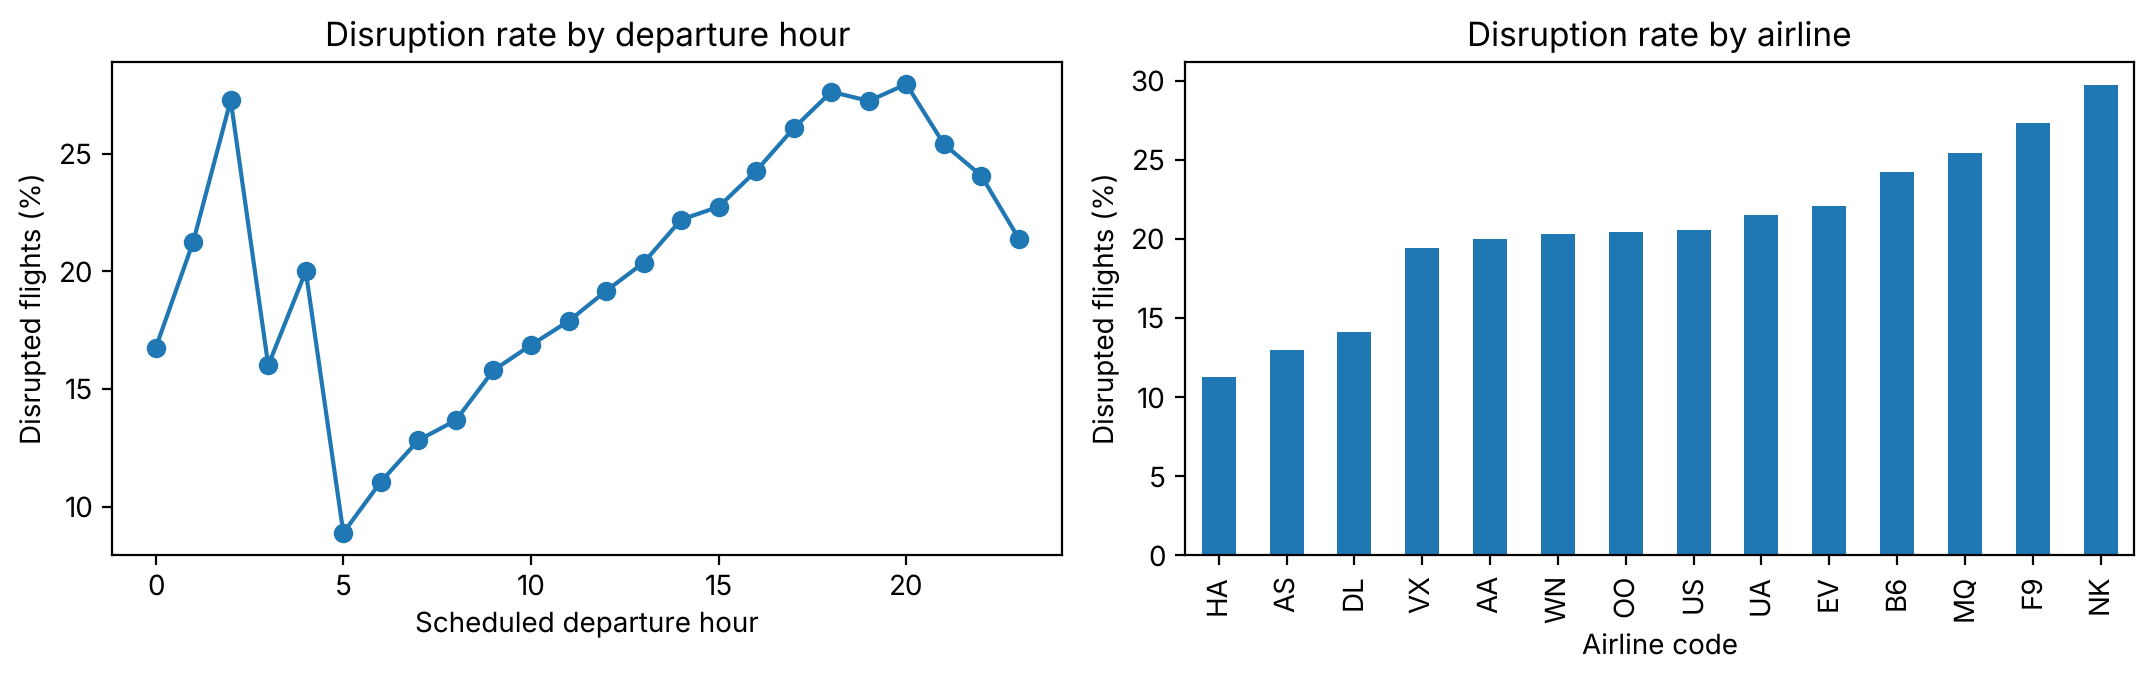

Highest hourly rate: 20 at 28.0 %
Lowest hourly rate: 5 at 8.9 %
Airline rate range: 11.3 to 29.7 %


In [6]:
explore = X_train.copy()
explore['DISRUPTED'] = y_train
hour_rate = explore.groupby('DEPARTURE_HOUR')['DISRUPTED'].mean() * 100
airline_rate = explore.groupby('AIRLINE')['DISRUPTED'].mean().sort_values() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
hour_rate.plot(ax=axes[0], marker='o', title='Disruption rate by departure hour')
airline_rate.plot.bar(ax=axes[1], title='Disruption rate by airline')
axes[0].set_xlabel('Scheduled departure hour')
axes[1].set_xlabel('Airline code')
for ax in axes:
    ax.set_ylabel('Disrupted flights (%)')
plt.tight_layout()
plt.show()
print('Highest hourly rate:', int(hour_rate.idxmax()), 'at', round(hour_rate.max(), 1), '%')
print('Lowest hourly rate:', int(hour_rate.idxmin()), 'at', round(hour_rate.min(), 1), '%')
print('Airline rate range:', round(airline_rate.min(), 1), 'to', round(airline_rate.max(), 1), '%')

**Findings:** disruption rate changes a lot between airlines (about 11% to 30%) and it is higher for evening flights. Early morning flights are disrupted less. Very early hours have few flights, so those points are less reliable.

## 5. Two models
- **Logistic regression:** a simple model that gives each input a weight.
- **Decision tree:** makes a series of yes/no questions (for example, "is departure after 17:00?").

Missing values are filled, numbers are scaled and the airline is turned into 0/1 columns. Both models use `class_weight='balanced'` because only about 20% of flights are disrupted.

In [7]:
number_steps = Pipeline([('fill', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
airline_steps = Pipeline([('fill', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore'))])
prepare = ColumnTransformer([('numbers', number_steps, numeric), ('airline', airline_steps, ['AIRLINE'])])

logistic = Pipeline([('prepare', prepare), ('model', LogisticRegression(class_weight='balanced', max_iter=500, random_state=42))])
tree = Pipeline([('prepare', prepare), ('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

## 6. Tuning and evaluation
We use GridSearchCV with 3 folds and the F1 score.
- Logistic regression: try C = 0.1, 1, 10
- Decision tree: try max_depth = 3, 5, 8

Metrics: precision = how many alerts are correct, recall = how many real disruptions we find, F1 = balance of both. Accuracy alone is misleading because most flights are normal.

In [8]:
logistic_search = GridSearchCV(logistic, {'model__C': [0.1, 1, 10]}, scoring='f1', cv=3)
tree_search = GridSearchCV(tree, {'model__max_depth': [3, 5, 8]}, scoring='f1', cv=3)
logistic_search.fit(X_train, y_train)
tree_search.fit(X_train, y_train)

comparison = pd.DataFrame([
    {'Model': 'Logistic regression', 'Validation F1': logistic_search.best_score_, 'Best setting': str(logistic_search.best_params_)},
    {'Model': 'Decision tree', 'Validation F1': tree_search.best_score_, 'Best setting': str(tree_search.best_params_)}
])
display(comparison.round(3))
if logistic_search.best_score_ >= tree_search.best_score_:
    best_model = logistic_search.best_estimator_
    best_name = 'Logistic regression'
else:
    best_model = tree_search.best_estimator_
    best_name = 'Decision tree'
print('Selected model:', best_name)

,Model,Validation F1,Best setting
0,Logistic regression,0.369,{'model__C': 0.1}
1,Decision tree,0.380,{'model__max_depth': 8}


Selected model: Decision tree


Accuracy     0.565
Precision    0.268
Recall       0.676
F1           0.384
Name: Final evaluation, dtype: float64

Always predicting normal gives accuracy: 0.799


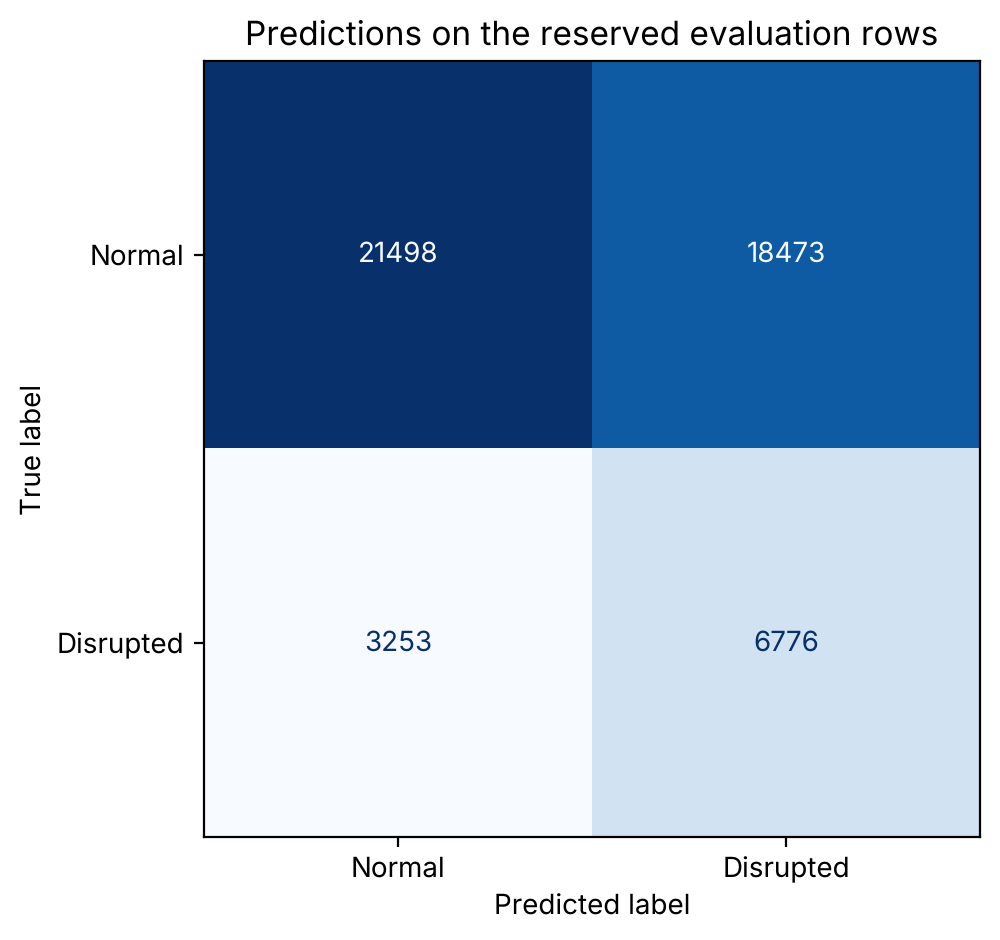

About 27 of every 100 alerts are correct.
About 68 of every 100 actual disruptions are found.


In [9]:
prediction = best_model.predict(X_test)
scores = pd.Series({
    'Accuracy': accuracy_score(y_test, prediction),
    'Precision': precision_score(y_test, prediction, zero_division=0),
    'Recall': recall_score(y_test, prediction, zero_division=0),
    'F1': f1_score(y_test, prediction, zero_division=0)
})
display(scores.round(3).rename('Final evaluation'))
print('Always predicting normal gives accuracy:', round(1 - y_test.mean(), 3))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=['Normal', 'Disrupted'], cmap='Blues', colorbar=False)
plt.title('Predictions on the reserved evaluation rows')
plt.tight_layout()
plt.show()
print(f'About {scores["Precision"] * 100:.0f} of every 100 alerts are correct.')
print(f'About {scores["Recall"] * 100:.0f} of every 100 actual disruptions are found.')

**Result:** the decision tree (max_depth 8) is chosen because it has the higher F1. On the test set it finds about 68% of disruptions, but many alerts are false (precision about 27%). For the business this means staff will check some normal flights, but they will catch most disrupted ones early. The model does not know the weather and uses 2015 data, so it is only a class example.

## 7. Save the model for the app

In [10]:
Path('models').mkdir(exist_ok=True)
joblib.dump(best_model, 'models/model.joblib')
print('Model saved to models/model.joblib')

Model saved to models/model.joblib


The app is in `app/streamlit_app.py`. Run it with `streamlit run app/streamlit_app.py`.

**References:** [Kaggle dataset](https://www.kaggle.com/datasets/usdot/flight-delays), [scikit-learn](https://scikit-learn.org/stable/user_guide.html), [Streamlit](https://docs.streamlit.io/).